# Seasonal Agriculture Performance Analysis
## Final Major Data Analytics Project

**Domain:** Agriculture & Data Analytics  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy



## 1. Executive Summary

This analysis evaluates **4,000 farm-level agricultural records** across **Kharif, Rabi, and Zaid** seasons. The project moves beyond generic exploratory analysis by investigating four decision-oriented dimensions:

1. **Agricultural performance** — yield and production  
2. **Economic performance** — revenue, cost, and profit  
3. **Resource efficiency** — water use and water efficiency  
4. **Seasonal drivers** — environmental conditions, crop mix, and irrigation practices

The notebook also includes statistical testing, crop-season comparisons, irrigation analysis, regional comparisons, and three student-designed analyses.


## 2. Problem Statement

Agricultural activities are influenced by seasonal variations in environmental conditions, farming practices, resource availability, and market conditions. Raw data alone does not clearly reveal how agricultural performance changes across seasons.

**The problem addressed in this project is to investigate seasonal differences in agricultural performance by identifying meaningful patterns, trends, relationships, and variations within the available dataset.**

The analysis focuses on evidence that can support better understanding and further investigation of seasonal agricultural planning.


## 3. Project Objectives

- Understand the dataset structure and data quality.
- Clean and prepare the data using justified decisions.
- Compare agricultural performance across seasons.
- Investigate environmental and resource-use differences.
- Examine economic outcomes across seasons.
- Analyze relationships between important variables.
- Compare crops, irrigation methods, and regions within seasons.
- Apply descriptive statistics, visualization, and statistical testing.
- Develop evidence-based insights, recommendations, and limitations.


## 4. Analytical Questions

This project investigates the following questions:

1. How do yield, production, and profit differ across seasons?
2. Are observed seasonal differences statistically meaningful?
3. How do environmental conditions vary across seasons?
4. How do water usage and water efficiency differ between seasons?
5. Which crops perform best economically within each season?
6. Does crop composition explain some apparent seasonal differences?
7. Which irrigation methods are associated with stronger profitability?
8. Are seasonal patterns consistent across states?
9. Which variables show the strongest relationships with yield and profit?
10. Where should stakeholders investigate further before making agricultural decisions?


In [1]:
# 5. Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

%matplotlib inline

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


In [2]:
# 6. Load Dataset

import pandas as pd

file_path = "seasonal_agriculture_performance_dataset.csv"

df_raw = pd.read_csv(file_path)
df = df_raw.copy()

print(f"Dataset loaded successfully: {file_path}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")

df.head()

Dataset loaded successfully: seasonal_agriculture_performance_dataset.csv
Shape: 4,000 rows × 28 columns


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Irrigation_Method,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.40,24.30,69.10,5.80,7.14,32.80,75.80,61.30,91.00,Drip,242.70,4.33,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.49,55.30
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.40,25.70,78.40,5.10,5.20,32.00,82.10,35.40,121.80,Flood,271.40,6.86,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.40,49.90
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.60,23.90,56.40,10.30,5.82,8.10,118.50,51.50,117.90,Drip,162.60,6.08,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.98,33.70
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.20,29.70,65.20,6.30,5.98,23.70,138.60,55.60,115.50,Rainfed,182.20,6.39,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.16,50.60
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.60,34.10,55.20,6.50,6.90,29.30,124.10,69.00,121.40,Flood,244.90,7.61,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.83,32.30


## 7. Initial Data Understanding

In [3]:
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (4000, 28)


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Irrigation_Method,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.40,24.30,69.10,5.80,7.14,32.80,75.80,61.30,91.00,Drip,242.70,4.33,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.49,55.30
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.40,25.70,78.40,5.10,5.20,32.00,82.10,35.40,121.80,Flood,271.40,6.86,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.40,49.90
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.60,23.90,56.40,10.30,5.82,8.10,118.50,51.50,117.90,Drip,162.60,6.08,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.98,33.70
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.20,29.70,65.20,6.30,5.98,23.70,138.60,55.60,115.50,Rainfed,182.20,6.39,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.16,50.60
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.60,34.10,55.20,6.50,6.90,29.30,124.10,69.00,121.40,Flood,244.90,7.61,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.83,32.30


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data_Type"))


Column names:
['Farm_ID', 'State', 'District', 'Crop', 'Season', 'Farm_Area_Hectares', 'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_pct', 'Sunlight_Hours_Day', 'Soil_pH', 'Soil_Moisture_pct', 'Nitrogen_kg_ha', 'Phosphorus_kg_ha', 'Potassium_kg_ha', 'Irrigation_Method', 'Fertilizer_kg_ha', 'Pesticide_Litre_ha', 'Seed_Quality_Score', 'Yield_Tonnes_Ha', 'Production_Tonnes', 'Market_Price_INR_Tonne', 'Total_Cost_INR', 'Revenue_INR', 'Profit_INR', 'Water_Used_m3', 'Water_Efficiency_t_per_1000m3', 'Disease_Pest_Risk_pct']

Data types:


,Data_Type
Farm_ID,str
State,str
District,str
Crop,str
Season,str
Farm_Area_Hectares,float64
Rainfall_mm,float64
Avg_Temperature_C,float64
Humidity_pct,float64
Sunlight_Hours_Day,float64


In [5]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Farm_ID,4000,4000,SF10001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,4000,8,Andhra Pradesh,529,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District,4000,10,Ludhiana,427,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,4000,8,Rice,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Season,4000,3,Kharif,1779,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Farm_Area_Hectares,"4,000.00",NaN,NaN,NaN,7.89,4.22,0.50,4.26,7.89,11.65,15.00
Rainfall_mm,"3,952.00",NaN,NaN,NaN,601.15,288.93,80.00,370.20,582.00,834.95,"1,395.20"
Avg_Temperature_C,"4,000.00",NaN,NaN,NaN,26.82,3.82,16.20,23.90,26.90,29.60,39.70
Humidity_pct,"4,000.00",NaN,NaN,NaN,63.21,11.96,25.00,54.77,63.00,71.90,95.00
Sunlight_Hours_Day,"4,000.00",NaN,NaN,NaN,7.32,1.12,3.50,6.60,7.30,8.10,11.00


### Variable Classification

The variables are grouped conceptually rather than treated as an undifferentiated list.

- **Identifier:** `Farm_ID`
- **Location:** `State`, `District`
- **Categorical farming context:** `Crop`, `Season`, `Irrigation_Method`
- **Environmental:** rainfall, temperature, humidity, sunlight, soil pH, soil moisture
- **Input/resource variables:** nutrients, fertilizer, pesticide, water
- **Performance:** yield, production, water efficiency
- **Economic:** market price, total cost, revenue, profit
- **Risk:** disease and pest risk

This classification helps keep the analysis focused on the actual project objective: seasonal agricultural performance.


## 8. Data Quality Analysis

In [6]:
# Missing values
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_summary[missing_summary["Missing_Count"] > 0])


,Missing_Count,Missing_Percentage
Rainfall_mm,48,1.20
Soil_Moisture_pct,40,1.00
Yield_Tonnes_Ha,32,0.80


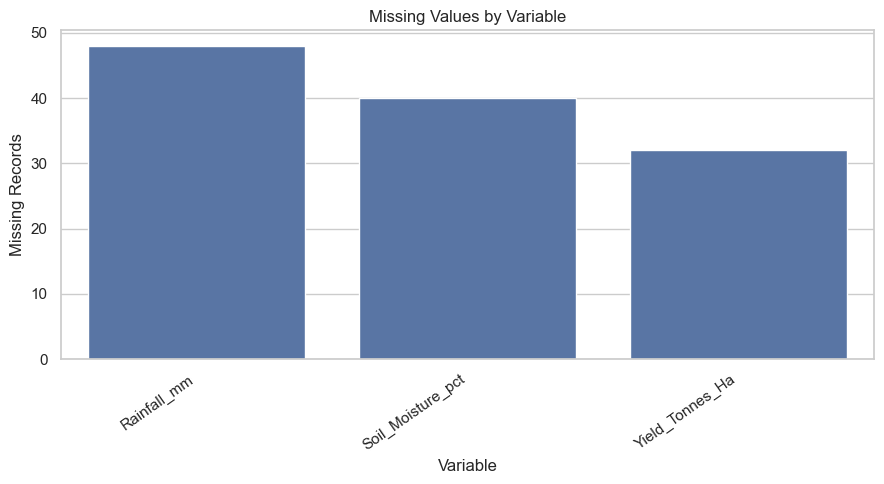

In [7]:
# Visualize missing values
missing_plot = missing_summary[missing_summary["Missing_Count"] > 0]

if not missing_plot.empty:
    plt.figure(figsize=(9, 5))
    sns.barplot(x=missing_plot.index, y=missing_plot["Missing_Count"])
    plt.xticks(rotation=35, ha="right")
    plt.title("Missing Values by Variable")
    plt.xlabel("Variable")
    plt.ylabel("Missing Records")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")


In [8]:
# Duplicate and structural checks
print("Duplicate rows:", df.duplicated().sum())
print("Unique Farm_ID values:", df["Farm_ID"].nunique())
print("Total records:", len(df))

print("\nCategorical values:")
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col} ({df[col].nunique()} unique):")
    print(df[col].dropna().unique())


Duplicate rows: 0
Unique Farm_ID values: 4000
Total records: 4000

Categorical values:

Farm_ID (4000 unique):
<ArrowStringArray>
['SF10001', 'SF10002', 'SF10003', 'SF10004', 'SF10005', 'SF10006', 'SF10007',
 'SF10008', 'SF10009', 'SF10010',
 ...
 'SF13991', 'SF13992', 'SF13993', 'SF13994', 'SF13995', 'SF13996', 'SF13997',
 'SF13998', 'SF13999', 'SF14000']
Length: 4000, dtype: str

State (8 unique):
<ArrowStringArray>
['Andhra Pradesh',    'Maharashtra',      'Telangana',      'Karnataka',
        'Gujarat',     'Tamil Nadu',         'Punjab', 'Madhya Pradesh']
Length: 8, dtype: str

District (10 unique):
<ArrowStringArray>
[  'Rajkot', 'Nalgonda', 'Warangal',   'Indore', 'Ludhiana',  'Raichur',
   'Guntur',  'Krishna',   'Nashik',    'Erode']
Length: 10, dtype: str

Crop (8 unique):
<ArrowStringArray>
[    'Wheat',     'Maize',    'Pulses',      'Rice',    'Cotton',    'Chilli',
 'Groundnut', 'Sugarcane']
Length: 8, dtype: str

Season (3 unique):
<ArrowStringArray>
['Kharif', 'Rabi', 

C:\Users\NIHAL CHAUDHARY\AppData\Local\Temp\ipykernel_27676\549947670.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


### Cleaning Decision

The dataset contains a small number of missing values in numerical variables. Because these records still contain useful information and the missingness is limited, the project uses **group-aware median imputation by Season and Crop**.

This is preferable to replacing values with zero and is more context-sensitive than a single global median. Any remaining missing values are filled using the overall median as a fallback.

No duplicate records are removed unless duplicates are actually detected.


In [9]:
# Remove exact duplicate records only if present
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)

# Group-aware median imputation for the known missing numerical variables
imputation_columns = [
    "Rainfall_mm",
    "Soil_Moisture_pct",
    "Yield_Tonnes_Ha"
]

for col in imputation_columns:
    if df[col].isna().sum() > 0:
        df[col] = (
            df[col]
            .fillna(df.groupby(["Season", "Crop"])[col].transform("median"))
            .fillna(df[col].median())
        )

print("Duplicates before cleaning:", duplicates_before)
print("Remaining missing values:", df.isna().sum().sum())
print("Final cleaned shape:", df.shape)


Duplicates before cleaning: 0
Remaining missing values: 0
Final cleaned shape: (4000, 28)


## 9. Feature Engineering

No unnecessary predictive features are created. The following analytical features are added to improve interpretability:

- **Profit Margin (%)** = Profit / Revenue × 100
- **Revenue per Hectare** = Revenue / Farm Area
- **Profit per Hectare** = Profit / Farm Area
- **Water Used per Hectare** = Water Used / Farm Area

These metrics allow comparisons between farms of different sizes.


In [10]:
# Avoid division by zero
area = df["Farm_Area_Hectares"].replace(0, np.nan)
revenue = df["Revenue_INR"].replace(0, np.nan)

df["Profit_Margin_pct"] = (df["Profit_INR"] / revenue) * 100
df["Revenue_per_Hectare"] = df["Revenue_INR"] / area
df["Profit_per_Hectare"] = df["Profit_INR"] / area
df["Water_Used_per_Hectare"] = df["Water_Used_m3"] / area

display(df[[
    "Farm_Area_Hectares", "Revenue_INR", "Profit_INR",
    "Profit_Margin_pct", "Revenue_per_Hectare",
    "Profit_per_Hectare", "Water_Used_per_Hectare"
]].head())


,Farm_Area_Hectares,Revenue_INR,Profit_INR,Profit_Margin_pct,Revenue_per_Hectare,Profit_per_Hectare,Water_Used_per_Hectare
0,0.53,30810,-11852,-38.47,"58,132.08","-22,362.26",447.17
1,6.53,40401,-451950,"-1,118.66","6,186.98","-69,211.33",758.50
2,4.86,190466,-124744,-65.49,"39,190.53","-25,667.49",262.35
3,4.50,200740,-95704,-47.68,"44,608.89","-21,267.56",852.00
4,4.21,193607,-144352,-74.56,"45,987.41","-34,287.89",780.76


## 10. Descriptive Statistical Analysis

In [11]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

statistical_summary = df[numeric_columns].describe().T
statistical_summary["Range"] = (
    statistical_summary["max"] - statistical_summary["min"]
)
statistical_summary["IQR"] = (
    statistical_summary["75%"] - statistical_summary["25%"]
)

display(statistical_summary.round(2))


,count,mean,std,min,25%,50%,75%,max,Range,IQR
Farm_Area_Hectares,"4,000.00",7.89,4.22,0.50,4.26,7.90,11.65,15.00,14.50,7.39
Rainfall_mm,"4,000.00",600.72,288.42,80.00,370.42,581.00,835.95,"1,395.20","1,315.20",465.52
Avg_Temperature_C,"4,000.00",26.82,3.82,16.20,23.90,26.90,29.60,39.70,23.50,5.70
Humidity_pct,"4,000.00",63.21,11.96,25.00,54.78,63.00,71.90,95.00,70.00,17.13
Sunlight_Hours_Day,"4,000.00",7.32,1.12,3.50,6.60,7.30,8.10,11.00,7.50,1.50
Soil_pH,"4,000.00",6.70,0.64,5.20,6.26,6.69,7.14,8.40,3.20,0.88
Soil_Moisture_pct,"4,000.00",26.51,6.70,8.00,21.70,26.40,31.30,47.00,39.00,9.60
Nitrogen_kg_ha,"4,000.00",120.25,31.22,40.00,98.50,120.10,141.22,220.00,180.00,42.72
Phosphorus_kg_ha,"4,000.00",57.78,17.02,15.00,46.20,57.50,69.40,120.00,105.00,23.20
Potassium_kg_ha,"4,000.00",104.76,27.74,30.00,86.20,105.10,123.60,200.00,170.00,37.40


In [12]:
seasonal_descriptive = df.groupby("Season").agg(
    Records=("Farm_ID", "count"),
    Avg_Yield=("Yield_Tonnes_Ha", "mean"),
    Median_Yield=("Yield_Tonnes_Ha", "median"),
    Avg_Production=("Production_Tonnes", "mean"),
    Avg_Revenue=("Revenue_INR", "mean"),
    Avg_Cost=("Total_Cost_INR", "mean"),
    Avg_Profit=("Profit_INR", "mean"),
    Median_Profit=("Profit_INR", "median"),
    Avg_Water_Used=("Water_Used_m3", "mean"),
    Avg_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean")
).round(2)

display(seasonal_descriptive)


,Records,Avg_Yield,Median_Yield,Avg_Production,Avg_Revenue,Avg_Cost,Avg_Profit,Median_Profit,Avg_Water_Used,Avg_Water_Efficiency
Season,,,,,,,,,,
Kharif,1779,5.63,1.95,46.31,"710,719.06","531,804.41","178,914.65","38,808.00","6,102.20",5.89
Rabi,1627,5.09,1.66,41.49,"601,526.05","513,836.58","87,689.47","-3,187.00","5,846.99",5.19
Zaid,594,4.64,1.45,38.89,"519,171.90","543,976.73","-24,804.82","-62,144.00","6,419.89",4.41


## 11. Univariate Analysis

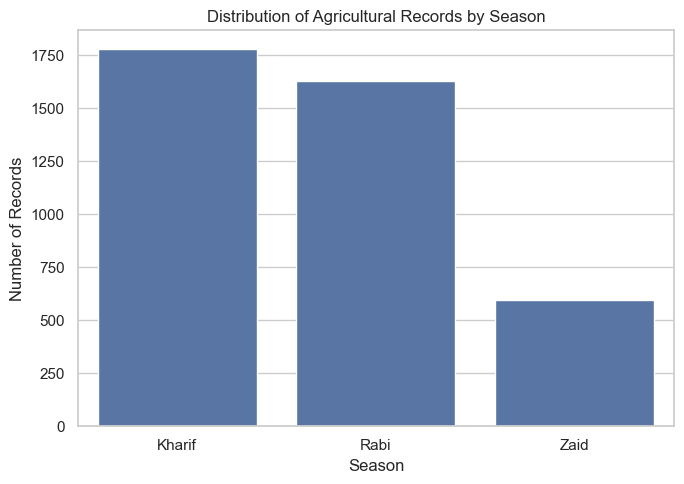

In [13]:
# Seasonal record distribution
plt.figure(figsize=(7, 5))
order = ["Kharif", "Rabi", "Zaid"]
sns.countplot(data=df, x="Season", order=order)
plt.title("Distribution of Agricultural Records by Season")
plt.xlabel("Season")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


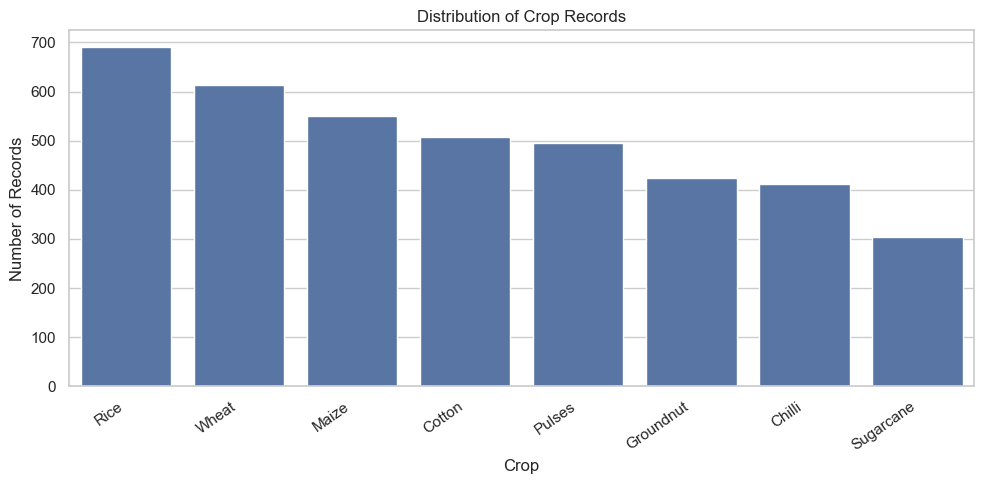

In [14]:
# Crop distribution
plt.figure(figsize=(10, 5))
crop_order = df["Crop"].value_counts().index
sns.countplot(data=df, x="Crop", order=crop_order)
plt.xticks(rotation=35, ha="right")
plt.title("Distribution of Crop Records")
plt.xlabel("Crop")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


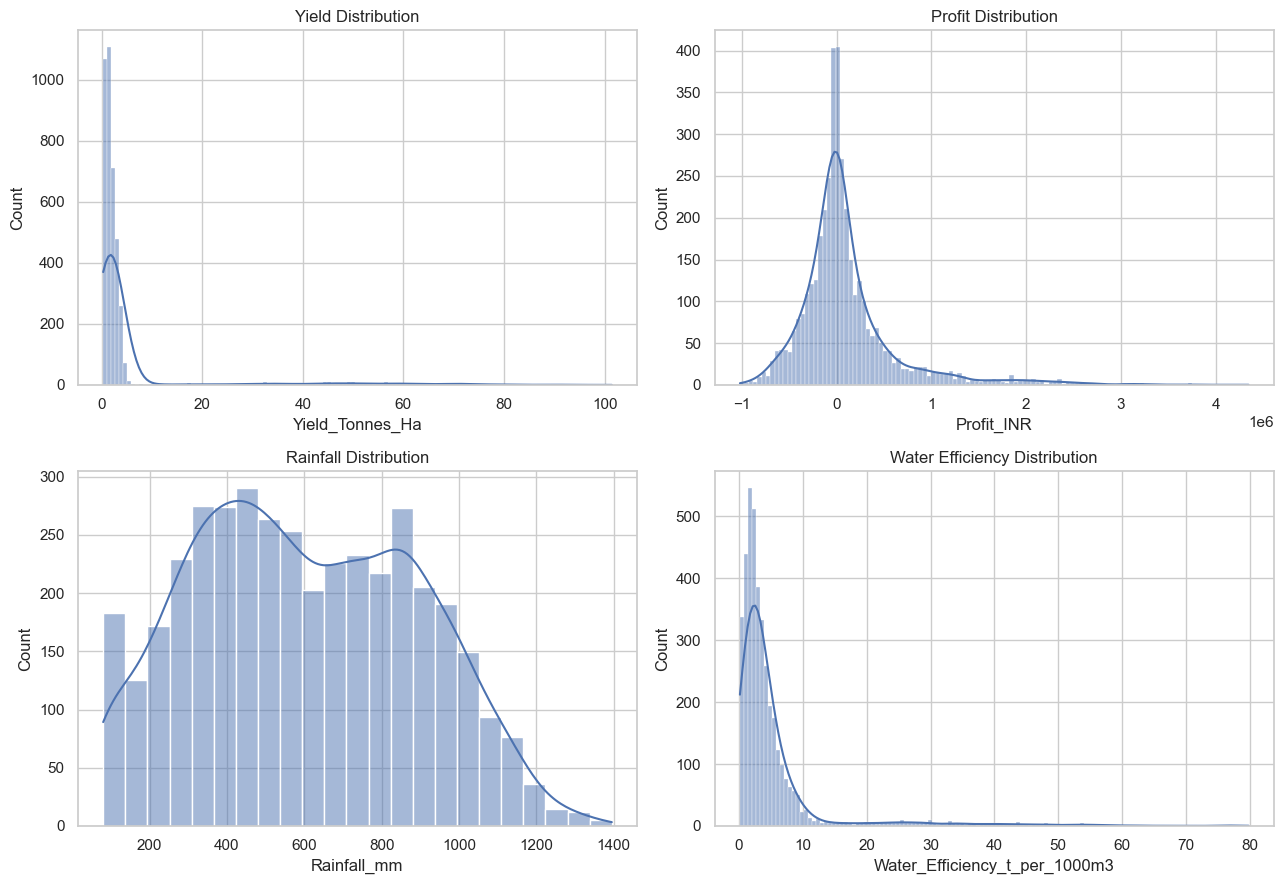

In [15]:
# Key distributions
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, column, title in zip(
    axes.flat,
    ["Yield_Tonnes_Ha", "Profit_INR", "Rainfall_mm", "Water_Efficiency_t_per_1000m3"],
    ["Yield Distribution", "Profit Distribution", "Rainfall Distribution", "Water Efficiency Distribution"]
):
    sns.histplot(data=df, x=column, kde=True, ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()


## 12. Outlier Investigation

In [16]:
# IQR-based outlier summary for key business variables
outlier_columns = [
    "Yield_Tonnes_Ha", "Production_Tonnes", "Profit_INR",
    "Water_Used_m3", "Revenue_INR"
]

outlier_results = []

for col in outlier_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_results.append({
        "Variable": col,
        "Potential_Outliers": count,
        "Percentage": round(count / len(df) * 100, 2),
        "Lower_Bound": lower,
        "Upper_Bound": upper
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)


,Variable,Potential_Outliers,Percentage,Lower_Bound,Upper_Bound
0,Yield_Tonnes_Ha,304,7.60,-1.63,5.52
1,Production_Tonnes,333,8.33,-23.98,53.36
2,Profit_INR,404,10.10,"-696,111.00","763,567.00"
3,Water_Used_m3,276,6.90,"-6,072.75","16,171.25"
4,Revenue_INR,240,6.00,"-736,519.00","1,780,911.00"


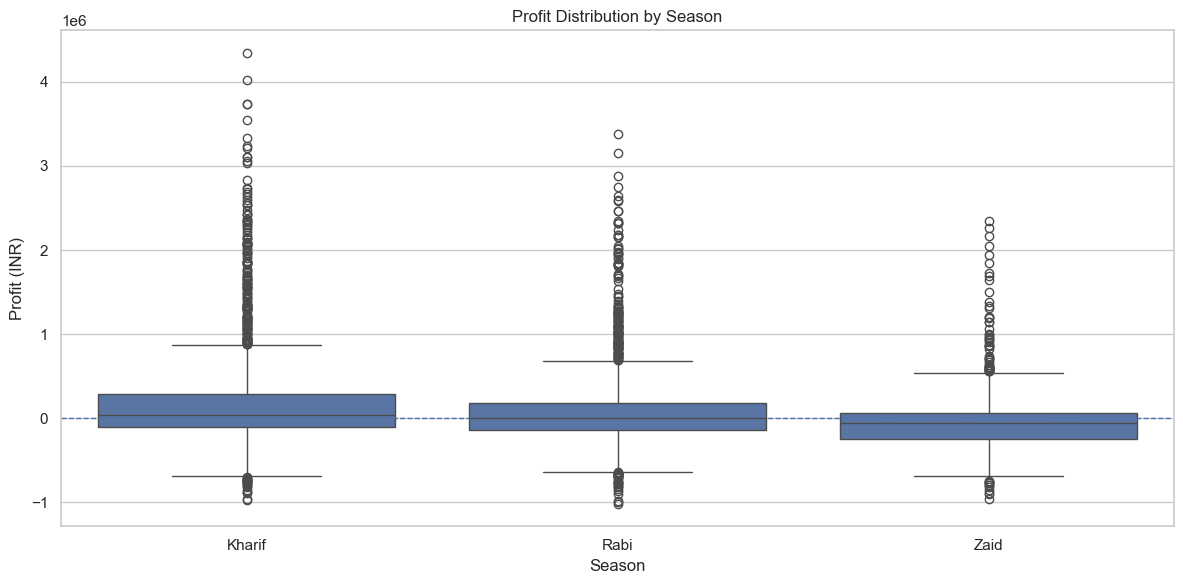

In [17]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x="Season",
    y="Profit_INR",
    order=["Kharif", "Rabi", "Zaid"]
)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Profit Distribution by Season")
plt.xlabel("Season")
plt.ylabel("Profit (INR)")
plt.tight_layout()
plt.show()


**Interpretation note:** Extreme values are not automatically deleted. In agriculture, unusually high production or profit may represent real crop-specific or farm-specific variation. The project therefore investigates these values rather than assuming they are data errors.


## 13. Bivariate Analysis: Season vs Performance

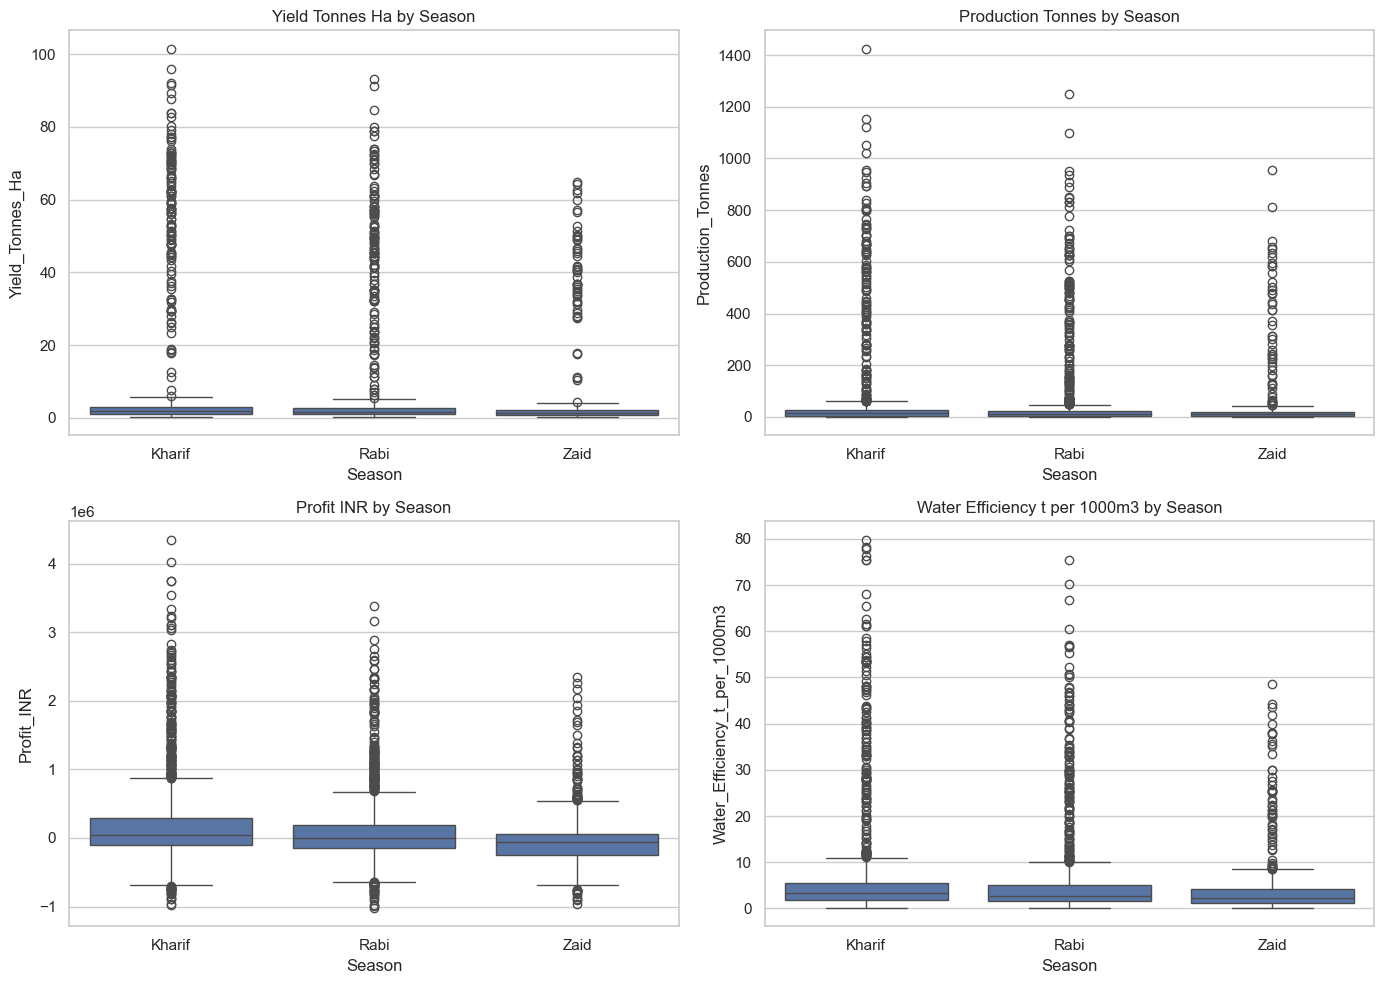

In [18]:
performance_metrics = [
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Profit_INR",
    "Water_Efficiency_t_per_1000m3"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, metric in zip(axes.flat, performance_metrics):
    sns.boxplot(
        data=df, x="Season", y=metric,
        order=["Kharif", "Rabi", "Zaid"], ax=ax
    )
    ax.set_title(f"{metric.replace('_', ' ')} by Season")
    ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.show()


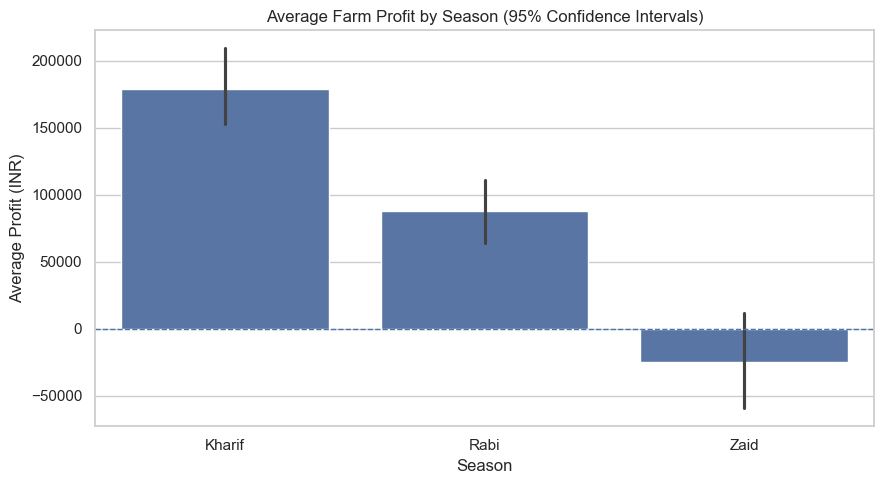

In [19]:
# Mean comparison with confidence intervals
plt.figure(figsize=(9, 5))
sns.barplot(
    data=df,
    x="Season",
    y="Profit_INR",
    order=["Kharif", "Rabi", "Zaid"],
    errorbar=("ci", 95)
)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Average Farm Profit by Season (95% Confidence Intervals)")
plt.xlabel("Season")
plt.ylabel("Average Profit (INR)")
plt.tight_layout()
plt.show()


## 14. Environmental Conditions Across Seasons

In [20]:
environmental_metrics = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_pct",
    "Sunlight_Hours_Day",
    "Soil_Moisture_pct"
]

environment_summary = (
    df.groupby("Season")[environmental_metrics]
    .mean()
    .round(2)
)

display(environment_summary)


,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_Moisture_pct
Season,,,,,
Kharif,852.10,28.45,71.81,6.79,31.20
Rabi,435.95,23.49,57.89,7.59,24.05
Zaid,299.16,31.04,52.01,8.18,19.18


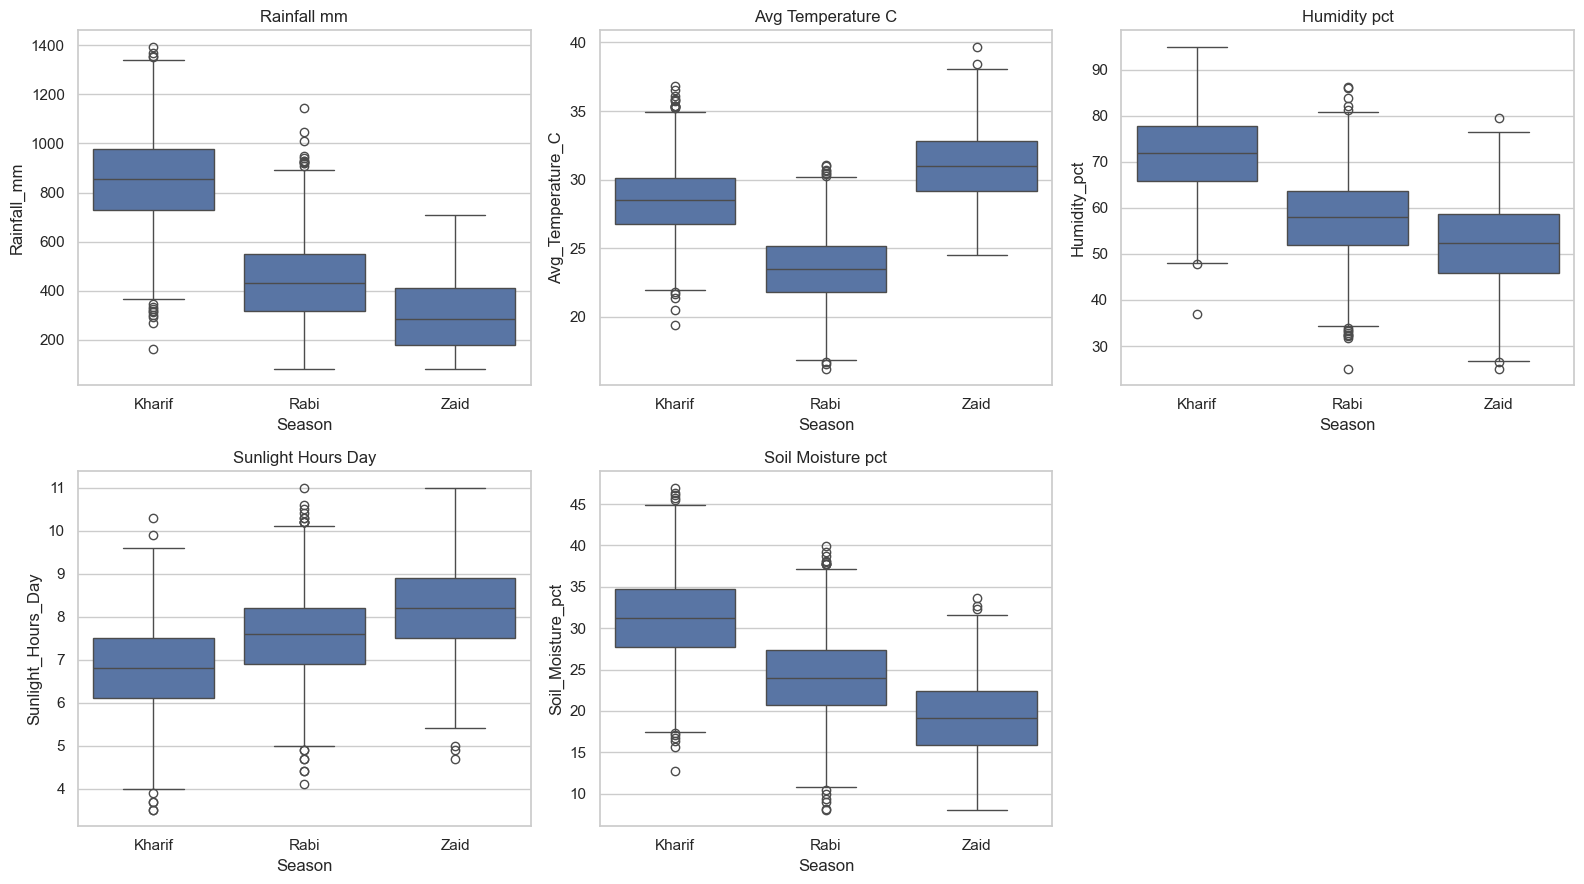

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, metric in zip(axes.flat, environmental_metrics):
    sns.boxplot(
        data=df, x="Season", y=metric,
        order=["Kharif", "Rabi", "Zaid"], ax=ax
    )
    ax.set_title(metric.replace("_", " "))

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


## 15. Resource Usage and Efficiency

In [22]:
resource_metrics = [
    "Water_Used_m3",
    "Water_Used_per_Hectare",
    "Fertilizer_kg_ha",
    "Pesticide_Litre_ha",
    "Water_Efficiency_t_per_1000m3"
]

resource_summary = (
    df.groupby("Season")[resource_metrics]
    .mean()
    .round(2)
)

display(resource_summary)


,Water_Used_m3,Water_Used_per_Hectare,Fertilizer_kg_ha,Pesticide_Litre_ha,Water_Efficiency_t_per_1000m3
Season,,,,,
Kharif,"6,102.20",758.17,187.08,5.08,5.89
Rabi,"5,846.99",763.36,185.41,5.02,5.19
Zaid,"6,419.89",792.58,184.64,5.17,4.41


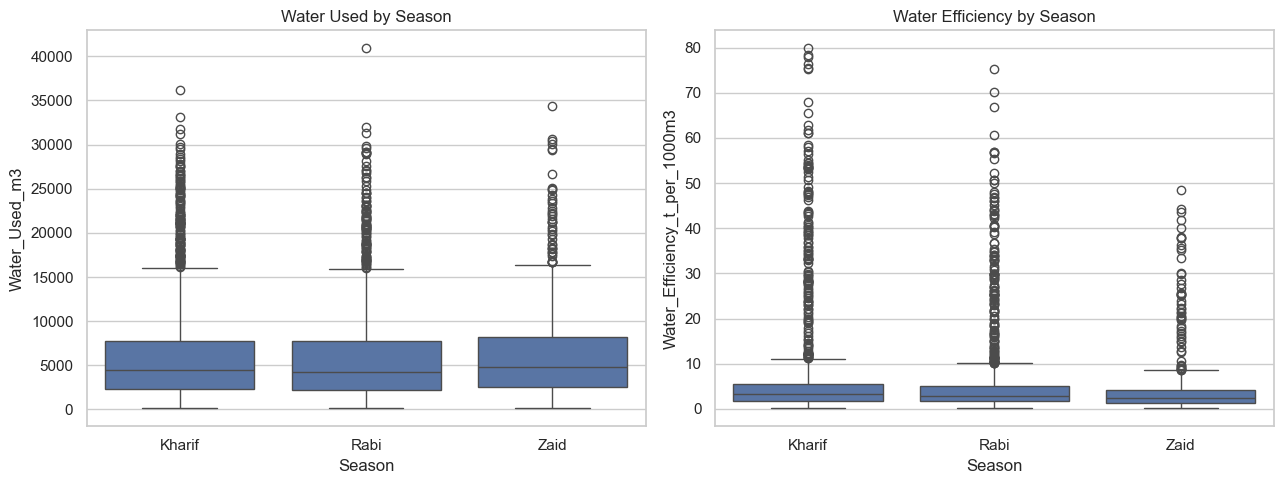

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df, x="Season", y="Water_Used_m3",
    order=["Kharif", "Rabi", "Zaid"], ax=axes[0]
)
axes[0].set_title("Water Used by Season")

sns.boxplot(
    data=df, x="Season", y="Water_Efficiency_t_per_1000m3",
    order=["Kharif", "Rabi", "Zaid"], ax=axes[1]
)
axes[1].set_title("Water Efficiency by Season")

plt.tight_layout()
plt.show()


## 16. Economic Performance Analysis

In [24]:
economic_summary = df.groupby("Season").agg(
    Average_Revenue=("Revenue_INR", "mean"),
    Average_Cost=("Total_Cost_INR", "mean"),
    Average_Profit=("Profit_INR", "mean"),
    Median_Profit=("Profit_INR", "median"),
    Total_Profit=("Profit_INR", "sum"),
    Average_Profit_Margin=("Profit_Margin_pct", "mean")
).round(2)

display(economic_summary)


,Average_Revenue,Average_Cost,Average_Profit,Median_Profit,Total_Profit,Average_Profit_Margin
Season,,,,,,
Kharif,"710,719.06","531,804.41","178,914.65","38,808.00",318289158,-38.64
Rabi,"601,526.05","513,836.58","87,689.47","-3,187.00",142670768,-44.27
Zaid,"519,171.90","543,976.73","-24,804.82","-62,144.00",-14734066,-69.35


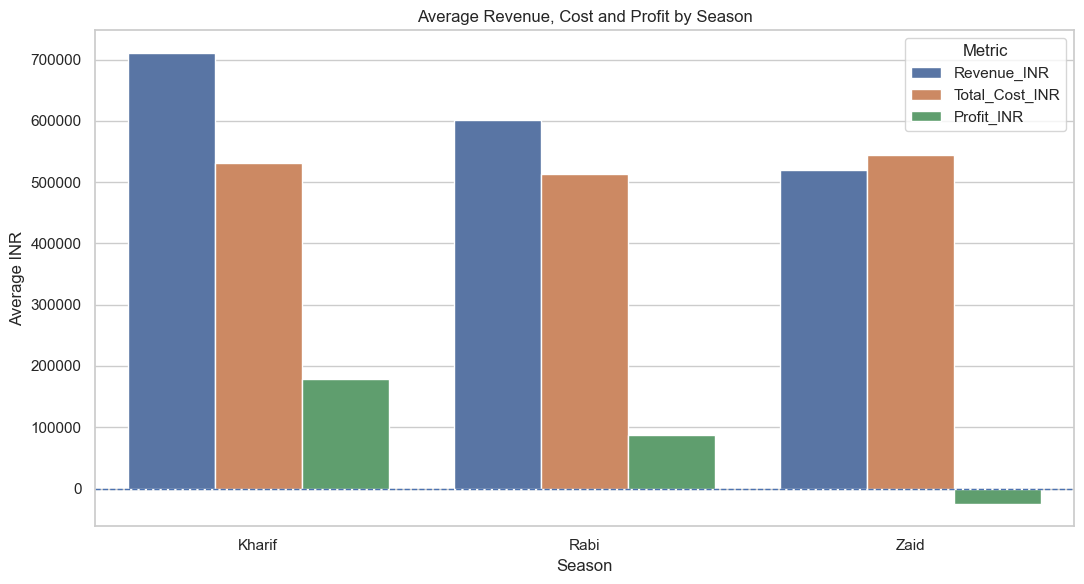

In [25]:
economic_long = (
    df.groupby("Season")[["Revenue_INR", "Total_Cost_INR", "Profit_INR"]]
    .mean()
    .reset_index()
    .melt(id_vars="Season", var_name="Metric", value_name="Average_INR")
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=economic_long,
    x="Season",
    y="Average_INR",
    hue="Metric",
    order=["Kharif", "Rabi", "Zaid"]
)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Average Revenue, Cost and Profit by Season")
plt.xlabel("Season")
plt.ylabel("Average INR")
plt.tight_layout()
plt.show()


## 17. Crop-Level Seasonal Performance

In [26]:
crop_season_summary = df.groupby(["Season", "Crop"]).agg(
    Records=("Farm_ID", "count"),
    Average_Yield=("Yield_Tonnes_Ha", "mean"),
    Average_Production=("Production_Tonnes", "mean"),
    Average_Profit=("Profit_INR", "mean"),
    Average_Profit_per_Hectare=("Profit_per_Hectare", "mean"),
    Average_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean")
).round(2)

display(crop_season_summary.sort_values(
    ["Season", "Average_Profit"], ascending=[True, False]
))


Records  Average_Yield  Average_Production  Average_Profit  \
Season Crop                                                                    
Kharif Sugarcane      125          53.46              446.07    1,000,790.81   
       Chilli         185           1.73               14.46      954,380.42   
       Cotton         215           1.37               10.41      216,999.55   
       Groundnut      193           1.48               10.49      108,265.44   
       Pulses         221           1.04                8.29       43,338.90   
       Maize          234           2.97               23.35      -39,332.67   
       Rice           314           2.71               22.45      -64,903.40   
       Wheat          292           2.26               18.31     -105,871.87   
Rabi   Sugarcane      129          43.96              365.26      731,612.86   
       Chilli         163           1.46               10.97      638,572.50   
       Cotton         201           1.19                9.44      107,343.59   
       Groundnut      177           1.22                9.06       10,416.54   
       Pulses         213           0.87                7.20      -14,309.14   
       Maize          233           2.62               21.59      -89,133.40   
       Rice           274           2.33               17.22      -98,427.87   
       Wheat          237           2.06               16.07     -119,954.57   
Zaid   Sugarcane       51          38.42              329.56      583,635.80   
       Chilli          64           1.18                9.98      448,659.09   
       Cotton          92           0.95                6.93      -53,925.34   
       Groundnut       54           1.04                8.62      -68,872.50   
       Pulses          62           0.65                4.94     -139,227.81   
       Wheat           85           1.75               14.06     -193,208.95   
       Maize           84           2.30               17.94     -194,049.17   
       Rice           102           1.90               15.11     -227,239.34   

                  Average_Profit_per_Hectare  Average_Water_Efficiency  
Season Crop                                                             
Kharif Sugarcane                  120,564.29                     36.00  
       Chilli                     111,812.03                      3.26  
       Cotton                      27,343.10                      2.13  
       Groundnut                   16,870.94                      3.58  
       Pulses                       7,043.55                      3.35  
       Maize                       -4,968.28                      6.05  
       Rice                        -7,986.98                      2.17  
       Wheat                      -13,181.57                      4.76  
Rabi   Sugarcane                   86,013.50                     27.92  
       Chilli                      85,696.18                      2.89  
       Cotton                      13,517.73                      1.94  
       Groundnut                    1,927.18                      2.90  
       Pulses                      -3,419.73                      2.70  
       Maize                      -11,776.24                      5.46  
       Rice                       -14,524.71                      1.84  
       Wheat                      -16,083.98                      4.69  
Zaid   Sugarcane                   68,049.98                     23.39  
       Chilli                      51,578.32                      2.20  
       Cotton                      -3,129.21                      1.49  
       Groundnut                   -8,168.15                      2.47  
       Pulses                     -18,905.27                      1.95  
       Wheat                      -25,222.79                      4.02  
       Maize                      -20,422.12                      4.75  
       Rice                       -25,266.34                      1.53

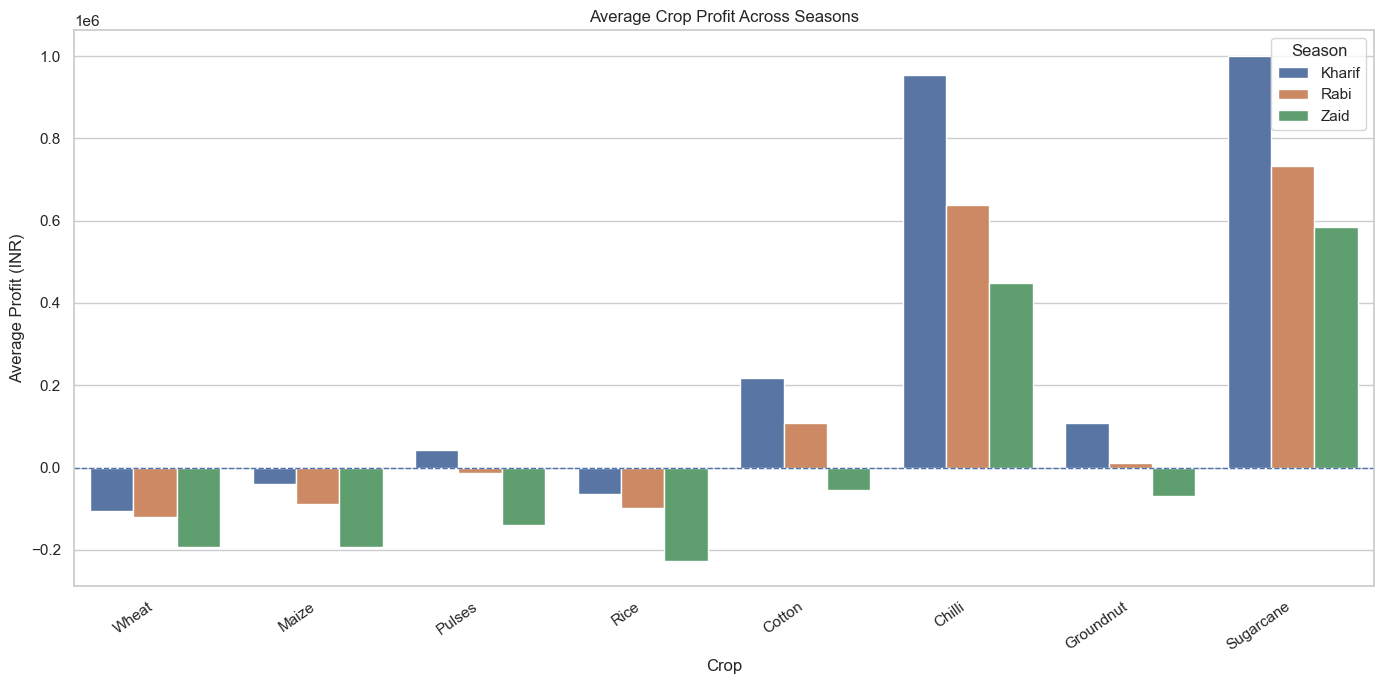

In [27]:
plt.figure(figsize=(14, 7))
sns.barplot(
    data=df,
    x="Crop",
    y="Profit_INR",
    hue="Season",
    hue_order=["Kharif", "Rabi", "Zaid"],
    errorbar=None
)
plt.axhline(0, linestyle="--", linewidth=1)
plt.xticks(rotation=35, ha="right")
plt.title("Average Crop Profit Across Seasons")
plt.xlabel("Crop")
plt.ylabel("Average Profit (INR)")
plt.tight_layout()
plt.show()


### Why crop-level analysis matters

A seasonal average can be strongly influenced by the mix of crops grown in that season. Therefore, crop-level comparisons are necessary before concluding that a season itself is responsible for better or worse performance.


## 18. Irrigation Method Analysis

In [28]:
irrigation_summary = df.groupby(
    ["Season", "Irrigation_Method"]
).agg(
    Records=("Farm_ID", "count"),
    Average_Yield=("Yield_Tonnes_Ha", "mean"),
    Average_Profit=("Profit_INR", "mean"),
    Average_Water_Used=("Water_Used_m3", "mean"),
    Average_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean")
).round(2)

display(irrigation_summary)


Records  Average_Yield  Average_Profit  \
Season Irrigation_Method                                           
Kharif Drip                   405           7.26      317,222.07   
       Flood                  590           4.98      133,373.83   
       Rainfed                463           5.70      158,974.13   
       Sprinkler              321           4.67      116,880.49   
Rabi   Drip                   370           6.35      187,843.22   
       Flood                  526           5.06       58,824.80   
       Rainfed                438           3.93       45,232.48   
       Sprinkler              293           5.31       76,502.07   
Zaid   Drip                   140           5.85       21,291.84   
       Flood                  194           3.97      -69,786.78   
       Rainfed                140           3.06      -79,467.26   
       Sprinkler              120           6.14       57,909.40   

                          Average_Water_Used  Average_Water_Efficiency  
Season Irrigation_Method                                                
Kharif Drip                         5,953.37                      6.80  
       Flood                        8,229.27                      3.64  
       Rainfed                      3,687.52                      8.85  
       Sprinkler                    5,863.27                      4.62  
Rabi   Drip                         5,911.41                      6.05  
       Flood                        7,766.83                      3.48  
       Rainfed                      3,298.29                      6.87  
       Sprinkler                    6,129.09                      4.64  
Zaid   Drip                         5,837.99                      5.30  
       Flood                        8,113.69                      2.73  
       Rainfed                      3,879.39                      5.48  
       Sprinkler                    7,324.41                      4.86

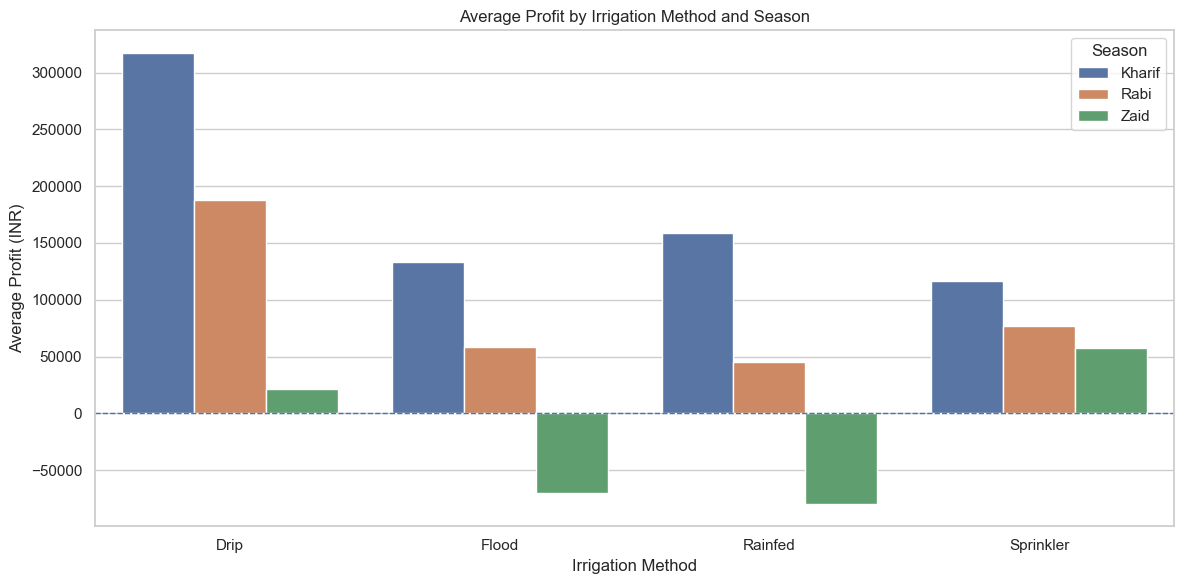

In [29]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x="Irrigation_Method",
    y="Profit_INR",
    hue="Season",
    hue_order=["Kharif", "Rabi", "Zaid"],
    errorbar=None
)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Average Profit by Irrigation Method and Season")
plt.xlabel("Irrigation Method")
plt.ylabel("Average Profit (INR)")
plt.tight_layout()
plt.show()


## 19. Regional Analysis

In [30]:
state_summary = df.groupby(["State", "Season"]).agg(
    Records=("Farm_ID", "count"),
    Average_Yield=("Yield_Tonnes_Ha", "mean"),
    Average_Profit=("Profit_INR", "mean")
).reset_index()

display(
    state_summary.sort_values(
        ["Season", "Average_Profit"], ascending=[True, False]
    )
)


,State,Season,Records,Average_Yield,Average_Profit
3,Gujarat,Kharif,221,6.34,"217,051.33"
18,Tamil Nadu,Kharif,206,5.52,"211,303.96"
6,Karnataka,Kharif,209,6.46,"201,226.21"
21,Telangana,Kharif,234,5.55,"199,668.38"
0,Andhra Pradesh,Kharif,240,5.68,"169,315.52"
12,Maharashtra,Kharif,222,5.43,"168,801.05"
9,Madhya Pradesh,Kharif,226,5.99,"134,242.40"
15,Punjab,Kharif,221,4.10,"133,779.10"
16,Punjab,Rabi,186,8.61,"169,294.52"
13,Maharashtra,Rabi,218,5.50,"159,581.50"


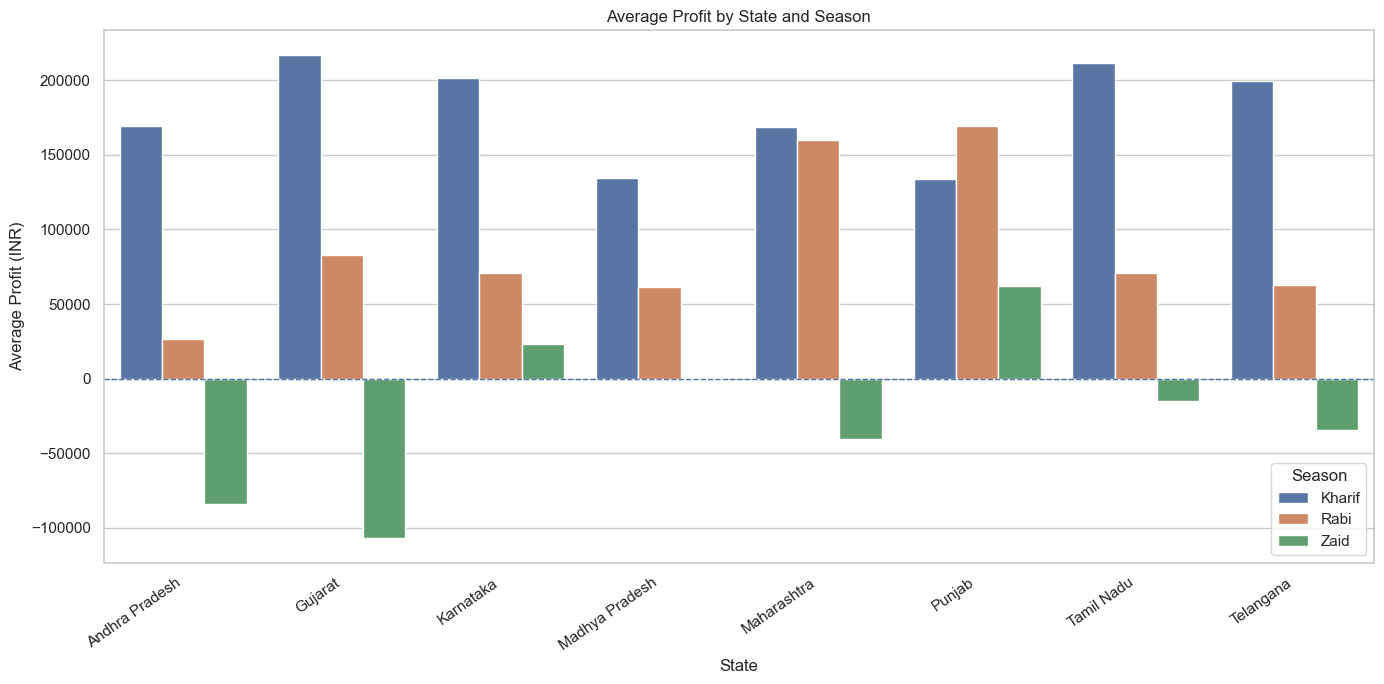

In [31]:
plt.figure(figsize=(14, 7))
sns.barplot(
    data=state_summary,
    x="State",
    y="Average_Profit",
    hue="Season",
    hue_order=["Kharif", "Rabi", "Zaid"]
)
plt.axhline(0, linestyle="--", linewidth=1)
plt.xticks(rotation=35, ha="right")
plt.title("Average Profit by State and Season")
plt.xlabel("State")
plt.ylabel("Average Profit (INR)")
plt.tight_layout()
plt.show()


## 20. Relationship Analysis

In [32]:
# Correlation with the two major analytical outcomes
numeric_df = df.select_dtypes(include=np.number)

yield_correlations = (
    numeric_df.corr()["Yield_Tonnes_Ha"]
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

profit_correlations = (
    numeric_df.corr()["Profit_INR"]
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

print("Top correlations with Yield:")
display(yield_correlations.head(12).to_frame("Correlation"))

print("\nTop correlations with Profit:")
display(profit_correlations.head(12).to_frame("Correlation"))


Top correlations with Yield:


,Correlation
Yield_Tonnes_Ha,1.00
Water_Efficiency_t_per_1000m3,0.92
Production_Tonnes,0.89
Revenue_per_Hectare,0.54
Profit_per_Hectare,0.54
Profit_INR,0.49
Water_Used_per_Hectare,0.48
Revenue_INR,0.43
Water_Used_m3,0.39
Market_Price_INR_Tonne,-0.38



Top correlations with Profit:


,Correlation
Profit_INR,1.00
Revenue_INR,0.89
Profit_per_Hectare,0.89
Revenue_per_Hectare,0.88
Production_Tonnes,0.55
Water_Efficiency_t_per_1000m3,0.49
Yield_Tonnes_Ha,0.49
Profit_Margin_pct,0.48
Market_Price_INR_Tonne,0.23
Water_Used_m3,0.19


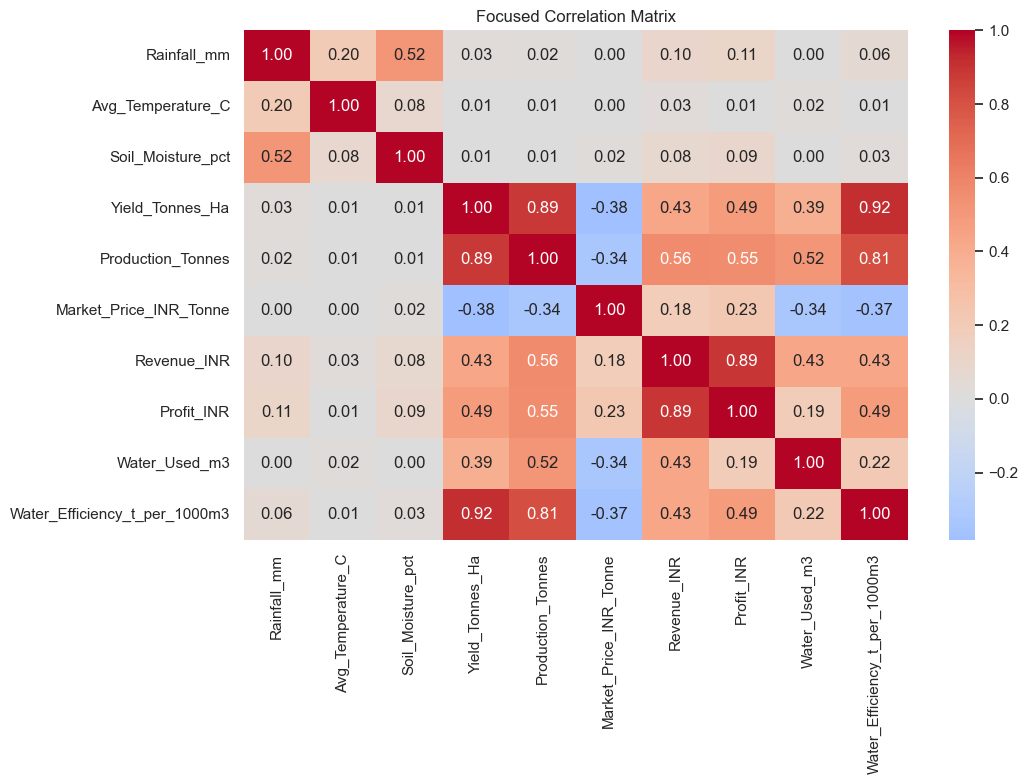

In [33]:
# Focused correlation heatmap to improve readability
focused_metrics = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Soil_Moisture_pct",
    "Yield_Tonnes_Ha",
    "Production_Tonnes",
    "Market_Price_INR_Tonne",
    "Revenue_INR",
    "Profit_INR",
    "Water_Used_m3",
    "Water_Efficiency_t_per_1000m3"
]

plt.figure(figsize=(11, 8))
sns.heatmap(
    df[focused_metrics].corr(),
    annot=True,
    fmt=".2f",
    center=0,
    cmap="coolwarm"
)
plt.title("Focused Correlation Matrix")
plt.tight_layout()
plt.show()


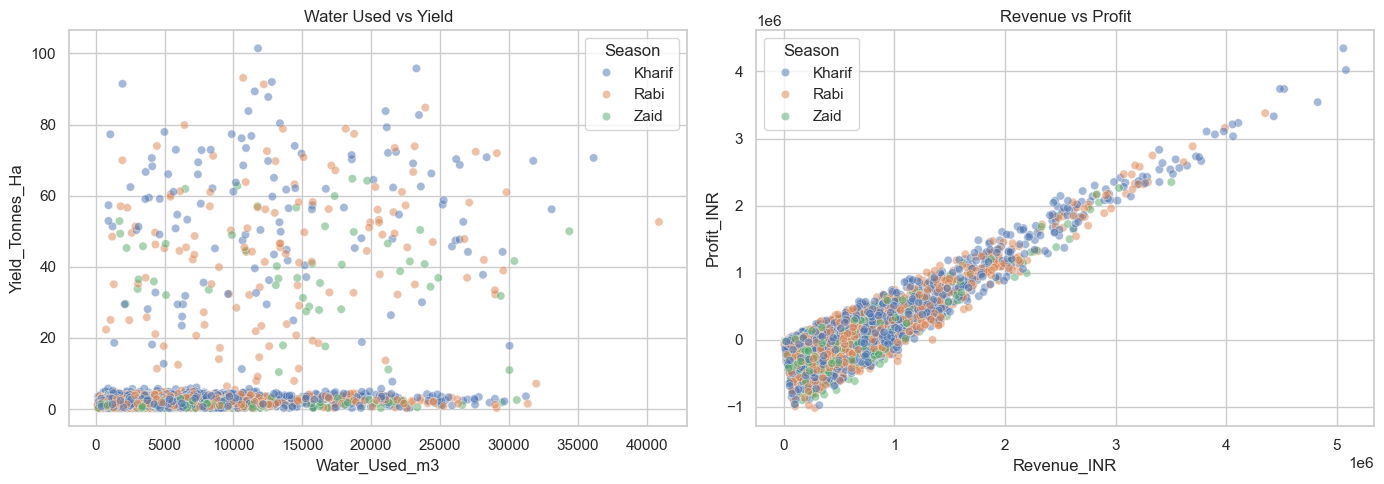

In [34]:
# Scatter relationships
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df,
    x="Water_Used_m3",
    y="Yield_Tonnes_Ha",
    hue="Season",
    alpha=0.5,
    ax=axes[0]
)
axes[0].set_title("Water Used vs Yield")

sns.scatterplot(
    data=df,
    x="Revenue_INR",
    y="Profit_INR",
    hue="Season",
    alpha=0.5,
    ax=axes[1]
)
axes[1].set_title("Revenue vs Profit")

plt.tight_layout()
plt.show()


## 21. Statistical Testing

The analysis uses one-way ANOVA to test whether the mean value of selected metrics differs across the three seasons.

- **Null hypothesis (H₀):** Seasonal means are equal.
- **Alternative hypothesis (H₁):** At least one seasonal mean differs.

A statistically significant result does not establish causation. It only indicates evidence of a difference in the observed dataset.


In [35]:
# One-way ANOVA across seasons
test_metrics = [
    "Yield_Tonnes_Ha",
    "Profit_INR",
    "Water_Efficiency_t_per_1000m3",
    "Rainfall_mm"
]

anova_results = []

for metric in test_metrics:
    groups = [
        group[metric].dropna().values
        for _, group in df.groupby("Season")
    ]

    statistic, p_value = stats.f_oneway(*groups)

    anova_results.append({
        "Metric": metric,
        "F_Statistic": statistic,
        "P_Value": p_value,
        "Statistically_Significant_at_5%": p_value < 0.05
    })

anova_df = pd.DataFrame(anova_results)
display(anova_df)


,Metric,F_Statistic,P_Value,Statistically_Significant_at_5%
0,Yield_Tonnes_Ha,1.46,0.23,False
1,Profit_INR,34.29,0.00,True
2,Water_Efficiency_t_per_1000m3,6.95,0.00,True
3,Rainfall_mm,"3,448.57",0.00,True


### Interpretation Framework

- If **p < 0.05**, the dataset provides statistical evidence that at least one seasonal group differs in mean value.
- If **p ≥ 0.05**, the analysis does not provide sufficient evidence to reject equal seasonal means.

This statistical test should be interpreted together with effect size, distributions, crop composition, and practical relevance.


## 22. Student-Designed Analysis 1 — Profitability Risk

### Question
**How does the proportion of profitable versus loss-making farms vary across seasons?**

Average profit alone can hide risk because a small number of highly profitable farms may increase the mean. This analysis examines the proportion of farms with positive and negative profit.


Profit_Status,Loss-making,Profitable
Season,,
Kharif,42.21,57.79
Rabi,51.14,48.86
Zaid,64.48,35.52


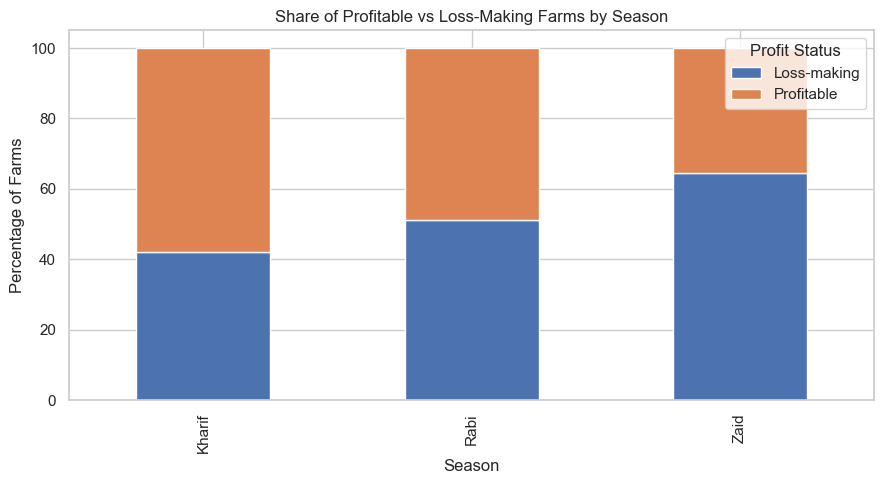

In [36]:
df["Profit_Status"] = np.where(
    df["Profit_INR"] >= 0,
    "Profitable",
    "Loss-making"
)

profit_status = (
    pd.crosstab(df["Season"], df["Profit_Status"], normalize="index") * 100
).round(2)

display(profit_status)

profit_status.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)
plt.title("Share of Profitable vs Loss-Making Farms by Season")
plt.xlabel("Season")
plt.ylabel("Percentage of Farms")
plt.legend(title="Profit Status")
plt.tight_layout()
plt.show()


## 23. Student-Designed Analysis 2 — Profit per Hectare

### Question
**Does seasonal profitability remain different after standardizing profit by farm area?**

Total profit can be affected by farm size. Profit per hectare provides a more comparable measure of economic performance.


,Average_Profit_per_Hectare,Median_Profit_per_Hectare
Season,,
Kharif,"21,881.81","8,340.45"
Rabi,"10,361.68",-894.33
Zaid,"-2,636.52","-13,760.26"


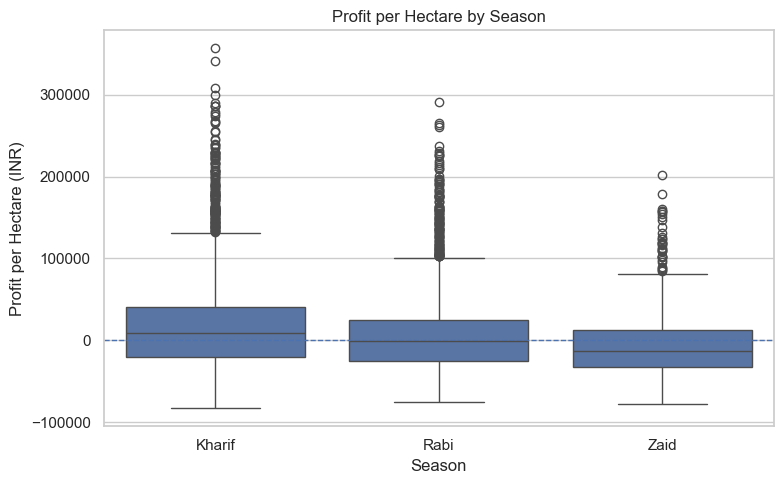

In [37]:
profit_per_hectare_summary = df.groupby("Season").agg(
    Average_Profit_per_Hectare=("Profit_per_Hectare", "mean"),
    Median_Profit_per_Hectare=("Profit_per_Hectare", "median")
).round(2)

display(profit_per_hectare_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Season",
    y="Profit_per_Hectare",
    order=["Kharif", "Rabi", "Zaid"]
)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Profit per Hectare by Season")
plt.xlabel("Season")
plt.ylabel("Profit per Hectare (INR)")
plt.tight_layout()
plt.show()


## 24. Student-Designed Analysis 3 — Seasonal Consistency Across Crops

### Question
**Are seasonal differences consistent across crops, or are they concentrated in particular crop types?**

This analysis prevents broad seasonal conclusions from being driven entirely by a small number of crops.


Season,Kharif,Rabi,Zaid
Crop,,,
Chilli,"954,380.42","638,572.50","448,659.09"
Cotton,"216,999.55","107,343.59","-53,925.34"
Groundnut,"108,265.44","10,416.54","-68,872.50"
Maize,"-39,332.67","-89,133.40","-194,049.17"
Pulses,"43,338.90","-14,309.14","-139,227.81"
Rice,"-64,903.40","-98,427.87","-227,239.34"
Sugarcane,"1,000,790.81","731,612.86","583,635.80"
Wheat,"-105,871.87","-119,954.57","-193,208.95"


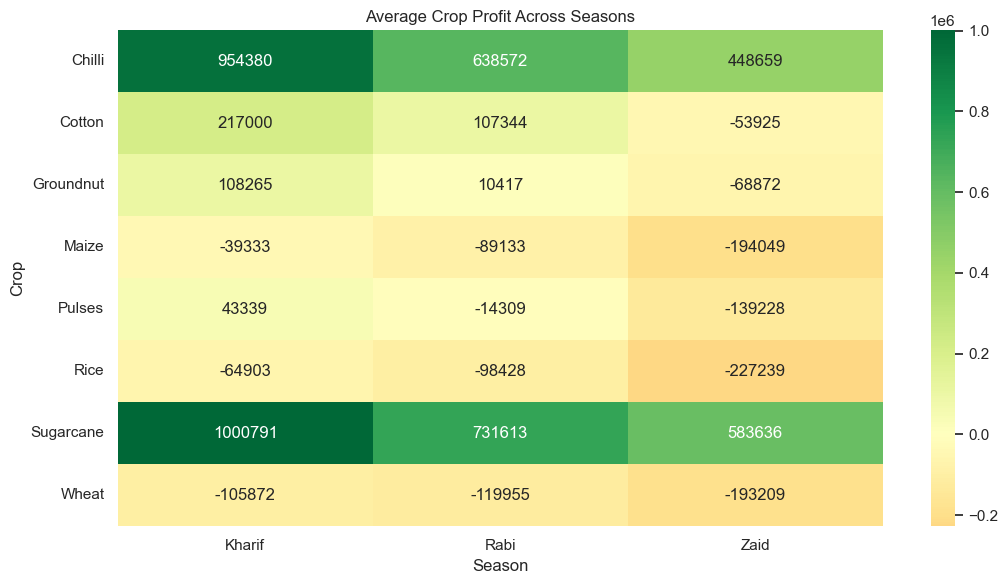

In [38]:
crop_profit_pivot = df.pivot_table(
    index="Crop",
    columns="Season",
    values="Profit_INR",
    aggfunc="mean"
).round(2)

# Order columns when available
crop_profit_pivot = crop_profit_pivot.reindex(
    columns=[c for c in ["Kharif", "Rabi", "Zaid"] if c in crop_profit_pivot.columns]
)

display(crop_profit_pivot)

plt.figure(figsize=(11, 6))
sns.heatmap(
    crop_profit_pivot,
    annot=True,
    fmt=".0f",
    center=0,
    cmap="RdYlGn"
)
plt.title("Average Crop Profit Across Seasons")
plt.xlabel("Season")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()


## 25. Seasonal Performance Scorecard

In [39]:
scorecard = df.groupby("Season").agg(
    Records=("Farm_ID", "count"),
    Avg_Yield=("Yield_Tonnes_Ha", "mean"),
    Avg_Production=("Production_Tonnes", "mean"),
    Avg_Revenue=("Revenue_INR", "mean"),
    Avg_Profit=("Profit_INR", "mean"),
    Median_Profit=("Profit_INR", "median"),
    Avg_Profit_per_Hectare=("Profit_per_Hectare", "mean"),
    Avg_Water_Used=("Water_Used_m3", "mean"),
    Avg_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean")
).round(2)

display(scorecard)


,Records,Avg_Yield,Avg_Production,Avg_Revenue,Avg_Profit,Median_Profit,Avg_Profit_per_Hectare,Avg_Water_Used,Avg_Water_Efficiency
Season,,,,,,,,,
Kharif,1779,5.63,46.31,"710,719.06","178,914.65","38,808.00","21,881.81","6,102.20",5.89
Rabi,1627,5.09,41.49,"601,526.05","87,689.47","-3,187.00","10,361.68","5,846.99",5.19
Zaid,594,4.64,38.89,"519,171.90","-24,804.82","-62,144.00","-2,636.52","6,419.89",4.41


## 26. Key Insights

The final insights below are based on the computed results in this notebook.

1. **Kharif has the strongest average economic outcome among the three seasons in this dataset.** Its average profit is substantially higher than Rabi and Zaid, but this should not automatically be interpreted as a purely seasonal effect because crop mix and other variables differ.

2. **Zaid shows the weakest average profitability and a negative median profit.** This indicates that loss-making outcomes are an important part of the Zaid-season distribution.

3. **Seasonal profit differences are statistically significant in the dataset.** The ANOVA test for profit provides evidence that at least one seasonal mean differs.

4. **Yield differences should be interpreted cautiously.** Crop-specific yield variation is substantial, and statistical testing may not support a strong overall seasonal yield difference even when mean values appear different.

5. **Water efficiency differs across seasons.** The analysis indicates that resource efficiency is not identical across seasonal conditions and should be considered alongside production and profit.

6. **Crop type is a major analytical context.** Crop-level comparisons show that profitability can vary dramatically within the same season; therefore, a seasonal average can conceal crop-specific outcomes.

7. **Irrigation outcomes are not uniform across seasons.** The same irrigation method can be associated with different economic outcomes under different seasonal and crop contexts.

8. **Profit is strongly related to revenue in the available data.** This is expected because profit is economically linked to revenue and cost; it should not be interpreted as an independent causal discovery.

9. **Potential outliers are analytically meaningful.** High-yield or high-profit observations may represent real agricultural differences rather than invalid data, so automatic removal would risk losing useful information.

10. **Seasonal planning requires multi-dimensional evaluation.** Yield alone is insufficient; profitability, water efficiency, risk, crop composition, and regional variation should be considered together.


## 27. Evidence-Based Recommendations

1. **Prioritize crop-season combinations rather than selecting a season based only on overall averages.** Crop-level results should guide deeper investigation.

2. **Investigate Zaid-season profitability risk.** The negative central tendency and distribution of profits justify examining crop choice, costs, water use, and market conditions more closely.

3. **Track water efficiency together with production.** Higher water use should not automatically be considered beneficial unless it is accompanied by meaningful productivity or economic value.

4. **Evaluate irrigation methods in context.** Recommendations about irrigation should be made separately for relevant crops and seasons rather than assuming one method is universally superior.

5. **Use profit per hectare for more comparable farm-level evaluation.** This reduces the influence of farm size when comparing economic outcomes.

6. **Treat statistically significant differences as starting points for investigation.** Statistical significance does not explain why a difference exists.

7. **Develop future analyses using additional contextual variables.** Weather timing, soil type, input prices, historical trends, and actual market conditions would strengthen real-world decision support.


## 28. Limitations

- The analysis is based only on the variables available in the provided dataset.
- The data appears to represent observations rather than a controlled experiment.
- Associations and correlations do not establish causation.
- Seasonal averages may be influenced by crop composition and farm characteristics.
- Outlier observations were retained because the dataset alone does not prove they are errors.
- Missing values were imputed; imputed values are estimates rather than original observations.
- The dataset does not provide enough contextual information to make universal agricultural recommendations.


## 29. Conclusion

This project demonstrates a structured approach to seasonal agricultural performance analysis using data cleaning, descriptive statistics, visualization, relationship analysis, statistical testing, and student-designed investigation.

The dataset reveals meaningful differences in economic outcomes, environmental conditions, and resource efficiency across Kharif, Rabi, and Zaid. However, the analysis also shows why broad conclusions should be treated carefully: crop mix, farm characteristics, and other contextual factors can influence apparent seasonal patterns.

The most useful outcome of the project is therefore not simply identifying a "best" season. It is developing an evidence-based framework for identifying **which crop-season-resource combinations deserve deeper investigation**.

This makes the analysis more useful for agricultural planning and demonstrates a professional data analytics workflow: **question → data quality → analysis → validation → interpretation → limitations → recommendations**.


## 30. Submission Checklist

- [x] Dataset loading
- [x] Dataset understanding
- [x] Data quality analysis
- [x] Missing-value treatment
- [x] Duplicate check
- [x] Feature review
- [x] Descriptive statistics
- [x] Univariate analysis
- [x] Outlier investigation
- [x] Bivariate analysis
- [x] Multivariate analysis
- [x] Correlation analysis
- [x] Seasonal comparison
- [x] Statistical testing
- [x] At least three student-designed analyses
- [x] Key insights
- [x] Evidence-based recommendations
- [x] Limitations
- [x] Final conclusion
